# Options building blocks: which option for which exposure

The book so far was hedged with futures only, so it could only fix the delta. To decide which
options position gives which exposure, and to hedge gamma and vega, start from the building
blocks: a call or a put, bought or sold, on one Brent futures contract.

Two rules to know by heart ([docs/Options.md](../docs/Options.md)):

1. **Buying or selling sets gamma, vega and theta.** Buy an option: long gamma, long vega,
   pays theta. Sell one: the opposite.
2. **Call or put sets the sign of the delta.** Long call +, long put −, short call −, short put +.

1. Payoffs at expiry
2. The greek signs, computed by the pricer
3. Delta and gamma across prices
4. Vega and theta across maturities
5. I want … → I do …, checked
6. Hedging the greeks: options for gamma, futures for delta

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Pricer, Quote
from cmdty.models.black76 import analytic_greeks
from cmdty.plotting import MUTED, SERIES, titles, use_style
from cmdty.strategies import option, position_greeks, straddle

use_style()

today = ql.Date(25, 11, 2026)
market = MarketData(today=today, rate=0.04, quotes={"BRENT": Quote(75.0, 0.32)})
pricer = Pricer(market=market)

U, CONTRACT, EXPIRY, K = "BRENT", "2027-03", "2027-02-25", 75.0  # 3-month ATM option

Vanilla options here, not APOs: a vanilla pays on the future's price at expiry, an APO on an
average. The greeks behave the same way, but the vanilla is simpler to read, and it is what a
desk uses to hedge gamma and vega. Priced with QuantLib's Black-76 formula (`ql.blackFormula`).

## 1. Payoffs at expiry

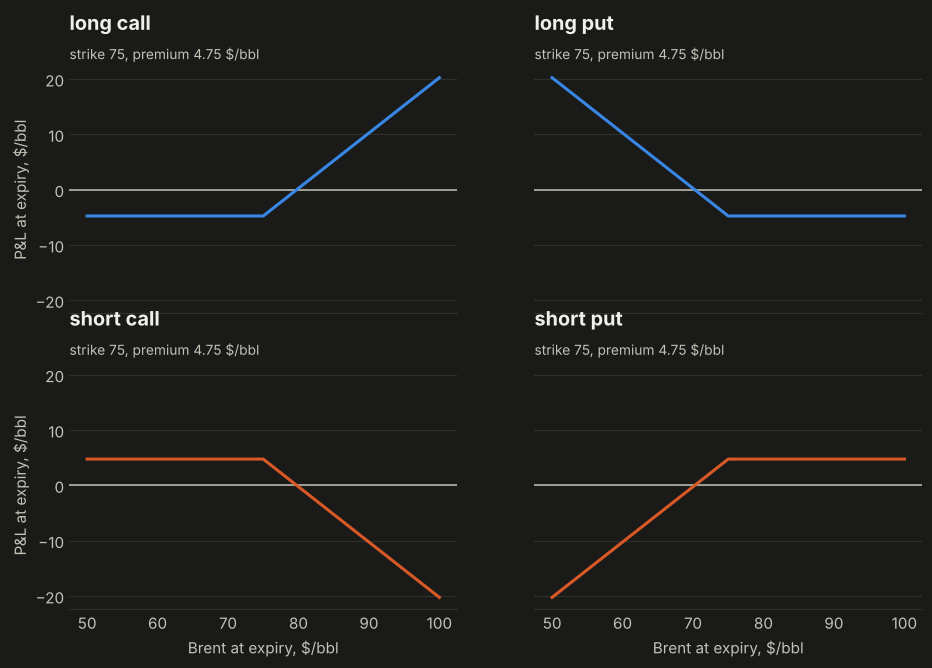

In [2]:
prices = np.linspace(50, 100, 201)
blocks = {
    "long call": ("call", +1), "long put": ("put", +1),
    "short call": ("call", -1), "short put": ("put", -1),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True)
for ax, (name, (kind, q)) in zip(axes.flat, blocks.items()):
    trade = option(name, U, CONTRACT, EXPIRY, K, kind, q)
    premium = pricer.pv(trade.instrument)
    payoff = q * (np.maximum((prices - K) if kind == "call" else (K - prices), 0) - premium)
    ax.set_axisbelow(True)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.plot(prices, payoff, color=SERIES[0] if q > 0 else SERIES[1], linewidth=2)
    titles(ax, name, f"strike {K:.0f}, premium {premium:.2f} $/bbl")
for ax in axes[1]:
    ax.set(xlabel="Brent at expiry, $/bbl")
for ax in axes[:, 0]:
    ax.set(ylabel="P&L at expiry, $/bbl")
plt.show()

- **Bought** (blue): the loss is capped at the premium; the gain grows with the move.
  That asymmetry is the gamma.
- **Sold** (orange): the premium is the best case; the loss grows with the move. The seller
  is paid to carry that risk.

## 2. The greek signs, computed by the pricer

Per bbl, bump-and-reprice greeks from the pricer (and a future for comparison: delta 1, no
other greek).

In [3]:
rows = {"future (long)": dict(delta=1.0, gamma=0.0, vega=0.0, theta=0.0)}
for name, (kind, q) in blocks.items():
    g = position_greeks([option(name, U, CONTRACT, EXPIRY, K, kind, q)], pricer, U)
    rows[name] = dict(delta=g.delta, gamma=g.gamma, vega=g.vega, theta=g.theta)

table = pd.DataFrame(rows).T
signs = table.map(lambda x: "+" if x > 1e-9 else ("−" if x < -1e-9 else "0"))
pd.concat({"value per bbl": table.round(4), "sign": signs}, axis=1)

value per bbl                          sign                 
                      delta   gamma    vega   theta delta gamma vega theta
future (long)        1.0000  0.0000  0.0000  0.0000     +     0    0     0
long call            0.5267  0.0327  0.1482 -0.0253     +     +    +     −
long put            -0.4633  0.0327  0.1482 -0.0253     −     +    +     −
short call          -0.5267 -0.0327 -0.1482  0.0253     −     −    −     +
short put            0.4633 -0.0327 -0.1482  0.0253     +     −    −     +

Exactly the two rules:

- **gamma, vega, theta** only depend on **bought or sold**: the long call and the long put
  share the same signs, so do the short ones
- **delta** depends on **call or put** (and on bought or sold)
- an ATM call has a delta near +0.5, an ATM put near −0.5

A check that the bump-and-reprice greeks are right: QuantLib's closed-form Black-76 greeks
(`ql.BlackCalculator`) give the same numbers.

In [4]:
opt = option("c", U, CONTRACT, EXPIRY, K, "call", 1).instrument
calc, a, df = pricer.risk(opt), analytic_greeks(opt, market), pricer.discount_factor(opt)
pd.DataFrame({
    "bump-and-reprice": [calc.delta(U), calc.gamma(U), calc.vega(U)],
    "QuantLib analytic": [df * a.delta, df * a.gamma, df * a.vega],
}, index=["delta", "gamma", "vega"]).round(5)

,bump-and-reprice,QuantLib analytic
delta,0.52667,0.52667
gamma,0.03267,0.03267
vega,0.14823,0.14823


## 3. Delta and gamma across prices

How the greeks of a long call and a long put change when the future moves, same strike.

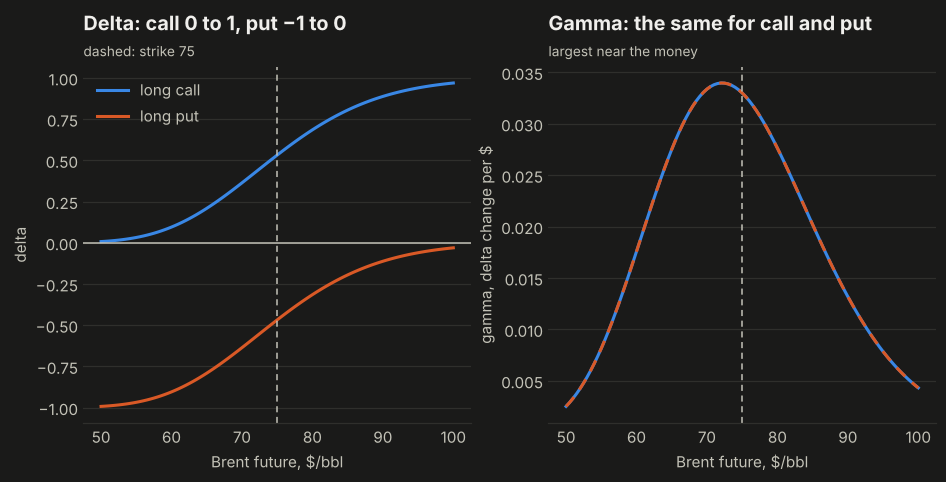

In [5]:
forwards = np.linspace(50, 100, 101)
curves = {k: {"delta": [], "gamma": []} for k in ("call", "put")}
for f in forwards:
    m = market.model_copy(update={"quotes": {U: Quote(f, 0.32)}})
    for kind in curves:
        g = analytic_greeks(option(kind, U, CONTRACT, EXPIRY, K, kind, 1).instrument, m)
        curves[kind]["delta"].append(g.delta)
        curves[kind]["gamma"].append(g.gamma)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for kind, color in (("call", SERIES[0]), ("put", SERIES[1])):
    axes[0].plot(forwards, curves[kind]["delta"], color=color, linewidth=2, label=f"long {kind}")
    axes[1].plot(forwards, curves[kind]["gamma"], color=color, linewidth=2,
                 linestyle="-" if kind == "call" else (0, (4, 3)), label=f"long {kind}")
for ax in axes:
    ax.set_axisbelow(True)
    ax.axvline(K, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set(xlabel="Brent future, $/bbl")
axes[0].axhline(0, color=MUTED, linewidth=1)
axes[0].set(ylabel="delta")
axes[1].set(ylabel="gamma, delta change per $")
axes[0].legend(frameon=False, loc="upper left")
titles(axes[0], "Delta: call 0 to 1, put −1 to 0", "dashed: strike 75")
titles(axes[1], "Gamma: the same for call and put", "largest near the money")
plt.show()

- **Delta of a call: between 0 and 1.** Far out of the money it barely moves with the price
  (near 0); deep in the money it moves like the future (near 1). **Put: between −1 and 0.**
- **Gamma is identical for the call and the put** (put-call parity: call − put = future, and a
  future has no gamma). It peaks **near the money** (slightly below the strike under a lognormal model), where the
  delta changes fastest.

## 4. Vega and theta across maturities

An ATM call, same strike, from one week to one year.

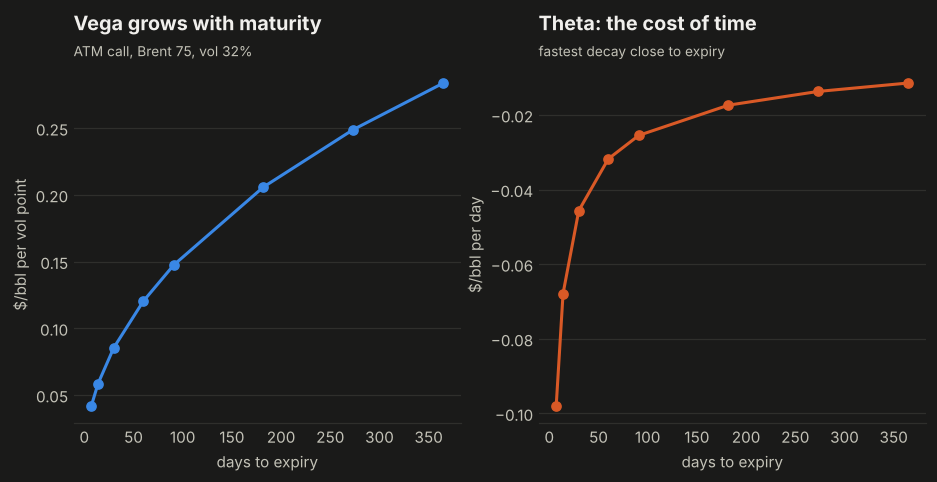

,price,vega,theta,gamma
days,,,,
7,1.3248,0.0414,-0.0981,0.1197
14,1.8720,0.0585,-0.0679,0.0846
30,2.7350,0.0854,-0.0456,0.0577
60,3.8538,0.1203,-0.0318,0.0406
91,4.7283,0.1474,-0.0255,0.0329
182,6.6134,0.2058,-0.0174,0.0229
273,8.0109,0.2487,-0.0137,0.0185
365,9.1601,0.2838,-0.0114,0.0158


In [6]:
days = [7, 14, 30, 60, 91, 182, 273, 365]
rows = []
for d in days:
    expiry = today + d
    opt = option("c", U, CONTRACT, expiry.ISO(), K, "call", 1).instrument
    calc = pricer.risk(opt)
    rows.append(dict(days=d, price=pricer.pv(opt), vega=calc.vega(U), theta=calc.theta(1),
                     gamma=calc.gamma(U)))
term = pd.DataFrame(rows).set_index("days")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].plot(term.index, term["vega"], color=SERIES[0], linewidth=2, marker="o")
axes[1].plot(term.index, term["theta"], color=SERIES[1], linewidth=2, marker="o")
for ax in axes:
    ax.set_axisbelow(True)
    ax.set(xlabel="days to expiry")
axes[0].set(ylabel="$/bbl per vol point")
axes[1].set(ylabel="$/bbl per day")
titles(axes[0], "Vega grows with maturity", "ATM call, Brent 75, vol 32%")
titles(axes[1], "Theta: the cost of time", "fastest decay close to expiry")
plt.show()
term.round(4)

- **Long vega → longer options.** Vega grows with maturity (roughly like √T): a one-year
  option is far more sensitive to vol than a one-week one.
- **Theta accelerates near expiry**, and so does gamma: short-dated options are the
  gamma tool, long-dated ones the vega tool. That is why a desk uses **two maturities** to
  hedge gamma and vega separately.

## 5. I want … → I do …, checked

Each line of the cheat sheet, computed: the sign of delta, gamma, vega and theta of the
position, 1 bbl each.

In [7]:
def futures_greeks(size):
    return dict(delta=size, gamma=0.0, vega=0.0, theta=0.0)

wants = {
    "long delta, no gamma: buy a future": None,
    "long delta + long gamma: buy a call": [option("c", U, CONTRACT, EXPIRY, K, "call", 1)],
    "short delta + long gamma: buy a put": [option("p", U, CONTRACT, EXPIRY, K, "put", 1)],
    "long delta + short gamma: sell a put": [option("p", U, CONTRACT, EXPIRY, K, "put", -1)],
    "short delta + short gamma: sell a call": [option("c", U, CONTRACT, EXPIRY, K, "call", -1)],
    "long gamma, no direction: buy a straddle": straddle(U, CONTRACT, EXPIRY, K, 1),
    "short gamma, collect theta: sell a straddle": straddle(U, CONTRACT, EXPIRY, K, -1),
}
rows = {}
for want, trades in wants.items():
    g = futures_greeks(1.0) if trades is None else vars(position_greeks(trades, pricer, U))
    rows[want] = {k: g[k] for k in ("delta", "gamma", "vega", "theta")}

def sign(x, band):
    if x == 0:
        return "0"
    return "+" if x > band else ("−" if x < -band else "≈ 0")

greeks_table = pd.DataFrame(rows).T
greeks_table.apply(lambda col: col.map(lambda x: sign(x, 0.1 if col.name == "delta" else 0)))

,delta,gamma,vega,theta
"long delta, no gamma: buy a future",+,0,0,0
long delta + long gamma: buy a call,+,+,+,−
short delta + long gamma: buy a put,−,+,+,−
long delta + short gamma: sell a put,+,−,−,+
short delta + short gamma: sell a call,−,−,−,+
"long gamma, no direction: buy a straddle",≈ 0,+,+,−
"short gamma, collect theta: sell a straddle",≈ 0,−,−,+


<small>Delta shown as ≈ 0 within ±0.1: the ATM straddle keeps a small delta (+0.06 per bbl)
because an at-the-money call has a delta slightly above 0.5 under Black-76.</small>

## 6. Hedging the greeks: options for gamma, futures for delta

A book that bought 10 000 bbl of a 3-month ATM straddle is long gamma. To bring the gamma to
zero:

1. **gamma with an option**: a future has no gamma, so sell an option. A 1-month ATM call
   (short-dated: a lot of gamma per unit)
2. **then the delta with futures**: they don't touch the gamma just fixed

In [8]:
book = straddle(U, CONTRACT, EXPIRY, K, 10_000)
hedge_opt = option("hedge call 1m", U, "2027-01", (today + 30).ISO(), K, "call", 1)

g_book = position_greeks(book, pricer, U)
g_unit = position_greeks([hedge_opt], pricer, U)
n_options = -g_book.gamma / g_unit.gamma          # bbl of the 1-month call to trade
with_options = book + [option("hedge call 1m", U, "2027-01", (today + 30).ISO(), K, "call",
                              n_options)]
g_step1 = position_greeks(with_options, pricer, U)
n_futures = -g_step1.delta                       # bbl of futures to trade
g_step2 = dict(vars(g_step1), delta=g_step1.delta + n_futures)

steps = pd.DataFrame({
    "book: long straddle": vars(g_book),
    f"+ {n_options:,.0f} bbl of 1m call": vars(g_step1),
    f"+ {n_futures:,.0f} bbl of futures": g_step2,
}).T[["delta", "gamma", "vega", "theta"]]
steps.round(1)

,delta,gamma,vega,theta
book: long straddle,633.8,653.3,2964.6,-506.6
"+ -11,322 bbl of 1m call",-5215.1,0.0,1997.6,10.1
"+ 5,215 bbl of futures",0.0,0.0,1997.6,10.1


Read the three lines:

- **The book**: long gamma and long vega, delta near zero, pays theta every day.
- **After selling the short-dated call**: gamma is zero. Because a short-dated option has a lot
  of gamma and little vega, most of the **vega stays**: the book is now a vega position, which
  is what a desk wanting to keep a view on vol would do. Selling the call also gave a
  **short delta**.
- **After the futures**: the delta is back to zero, gamma untouched.

Notice the **theta**: from −507 $ a day to about zero. Theta comes with gamma: once the
gamma is gone, the book no longer pays for time. That is why theta is never hedged on its own.

To remove the vega as well, a second option with a different maturity is needed: two options,
two equations (gamma = 0, vega = 0), then futures for the delta. That is the next step of the
hedging bot.

## In two lines

- **Bought → long gamma and vega, pays theta; sold → the opposite. Call or put → sign of the
  delta.**
- **Options fix gamma and vega, futures fix the delta, in that order.**